# log_engine : rapport du projet final Python ING3

**Sujet :** engine de traitement et d'analyse de flux de données sécurisé.

**Groupe 6 :** Amine Chamekh, Yacine Chemlali, Fidèle Danton, Badara Diallo (ECE, ING3).

## Le projet en une minute

On reçoit de gros fichiers de logs (des journaux d'un serveur). Chaque ligne ressemble à ça :

```text
2026-11-04T05:50:03 | ERROR | 192.168.1.18:22/SSH | user=u008 | {"event": "login_failed", "level": "ERROR", "code": 401}
   date et heure       niveau   IP : port / protocole   utilisateur   payload (JSON ou texte)
```

Notre programme lit ces fichiers **sans jamais les charger en entier en mémoire**, enlève les lignes cassées, nettoie le reste, compte tout, repère les IP dangereuses et les attaques par force brute, puis écrit un rapport.

Le trajet d'une ligne, du fichier au rapport :

```text
fichiers .log
   │  Module 1  ingestion.py    yield / yield from : une ligne à la fois
   ▼
lignes de texte ──► parse_line ──► dictionnaire (ou None si la ligne est cassée)
   │  Module 2  pipeline.py     filter(None) ► map(normalize) ► filter(lambda) ► map(categorize)
   ▼
logs propres
   ├──► Module 3  aggregation.py  compteurs defaultdict, set / frozenset, force brute
   └──► Module 4  rules.py        apply_security_rules(*règles, **réglages)
                  audit.py        globals() / locals()
   ▼
rapport.json + affichage dans le terminal        (main.py pilote tout)
```

## Où trouver chaque critère du barème

| Critère (points) | Ce qui le prouve | Fichier |
| --- | --- | --- |
| 1. Environnement et livrables (2) | `venv`, `requirements.txt` par `pip freeze`, code en `.py`, notebooks pour la démo | racine |
| 2. Mémoire et générateurs (4) | `read_log_file` (`yield`), `read_many_files` (`yield from`), mesure du pic mémoire | `ingestion.py` |
| 3. Structures de données (4) | tuple `ConnectionMeta`, `match-case` dans `route`, `set` / `frozenset`, `defaultdict` | `config.py`, `pipeline.py`, `aggregation.py` |
| 4. Programmation fonctionnelle (4) | `filter`, `map`, `lambda`, règles passées en argument | `pipeline.py`, `rules.py` |
| 5. Moteur de règles et introspection (3) | `apply_security_rules(*args, **kwargs)`, `audit_scope(locals())` et `globals()` | `rules.py`, `audit.py` |
| 6. Qualité et robustesse (3) | PEP8 (`black`, `flake8`), typage (`mypy`), exceptions, `else` de boucle, 67 tests | partout |

Ce notebook ne contient **aucun code du projet** : il importe `log_engine` et montre que chaque critère fonctionne.

In [1]:
import json
import os
import subprocess
import sys
import tracemalloc
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt

# Le notebook tourne dans notebooks/ : on se place à la racine du projet
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

from log_engine.aggregation import aggregate, compare_ips, detect_brute_force, load_blacklist
from log_engine.audit import audit_scope
from log_engine.config import ALLOWED_PORTS, NIGHT_END_HOUR, ConnectionMeta
from log_engine.ingestion import parse_line, parse_stream, read_log_file, read_many_files
from log_engine.pipeline import build_pipeline, categorize, normalize, route
from log_engine.rules import RULES, apply_security_rules

FILES = ["data/app_logs_1.log", "data/app_logs_2.log"]
blacklist = load_blacklist("data/blacklist.txt")
Path("output").mkdir(exist_ok=True)


def run(*command):
    # Lance une commande du projet et rend sa sortie texte
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}
    result = subprocess.run(command, capture_output=True, encoding="utf-8", env=env)
    return result.stdout + result.stderr

## Critère 1 : environnement et livrables (2 pts)

**Ce que demande le sujet :** un environnement virtuel isolé, un `requirements.txt` issu de `pip freeze`, du code en `.py` et les notebooks réservés au prototypage et à la démo.

**Ce qu'on a fait :**

```bash
python -m venv venv
venv\Scripts\activate          # Linux / macOS : source venv/bin/activate
pip install -r requirements.txt
pip freeze > requirements.txt  # c'est comme ça qu'on l'a généré
```

- Tout le code est dans le package `log_engine/` et dans `main.py`. Le dossier `notebooks/` ne contient que `prototypage.ipynb` (nos essais) et ce rapport.
- Le cœur du projet n'utilise **que la bibliothèque standard**. Les paquets du `requirements.txt` servent aux tests (`pytest`), au style (`black`, `flake8`, `mypy`), aux graphiques (`matplotlib`) et à Jupyter.

Preuve : ce notebook tourne bien dans le `venv` du projet.

In [2]:
print("Python utilisé :", Path(sys.executable).relative_to(Path.cwd()))
print("Dans un venv :", sys.prefix != sys.base_prefix)
packages = Path("requirements.txt").read_text(encoding="utf-8").split()
print("Paquets figés dans requirements.txt :", len(packages))

Python utilisé : venv\Scripts\python.exe
Dans un venv : True
Paquets figés dans requirements.txt : 123


## Critère 2 : gestion mémoire et générateurs (4 pts)

**Ce que demande le sujet :** lire les logs avec `yield`, enchaîner plusieurs fichiers avec `yield from`, sans charger tout le jeu de données en RAM.

**Ce qu'on a fait** (`ingestion.py`) :

- `read_log_file(path)` ouvre le fichier et rend **une ligne à la fois** avec `yield`. Tant que personne ne demande la ligne suivante, rien n'est lu.
- `read_many_files(paths)` enchaîne plusieurs fichiers avec `yield from read_log_file(path)`. Si un fichier manque, on affiche un avertissement et on passe au suivant.
- Toute la chaîne (`parse_stream`, `filter`, `map`) est faite de générateurs : **aucune liste de logs n'est jamais construite**.

Un générateur pèse quelques centaines d'octets, quelle que soit la taille du fichier. La liste des mêmes lignes pèse bien plus (et `sys.getsizeof` ne compte même pas le texte, seulement les références).

In [3]:
generator = read_log_file(FILES[0])
all_lines = list(read_log_file(FILES[0]))
print("Générateur :", sys.getsizeof(generator), "octets")
print("Liste de", len(all_lines), "lignes :", sys.getsizeof(all_lines), "octets, sans compter le texte")

# yield from : les deux fichiers lus comme un seul flux
print("Lignes des 2 fichiers enchaînés :", sum(1 for _ in read_many_files(FILES)))

Générateur : 232 octets
Liste de 1013 lignes : 8856 octets, sans compter le texte
Lignes des 2 fichiers enchaînés : 2024


**La vraie preuve : la mémoire ne grossit pas avec le fichier.** On génère un fichier de 1 000 lignes puis un de 20 000 lignes, et on mesure le pic mémoire de la lecture avec `tracemalloc`.

In [4]:
def measure_reading(path):
    tracemalloc.start()
    count = 0
    for record in parse_stream(read_log_file(path)):
        count = count + 1
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return count, peak


for lines in (1000, 20000):
    path = f"output/mesure_{lines}.log"
    run(sys.executable, "scripts/generate_logs.py", path, "--lines", str(lines))
    count, peak = measure_reading(path)
    size = Path(path).stat().st_size
    print(f"{count:>6} lignes | {size // 1024:>5} Ko sur le disque | pic mémoire {peak // 1024} Ko")

  1013 lignes |    95 Ko sur le disque | pic mémoire 34 Ko


 20013 lignes |  1883 Ko sur le disque | pic mémoire 42 Ko


Le fichier est 20 fois plus gros, le pic mémoire reste presque le même : c'est exactement l'intérêt des générateurs.

On a aussi lancé `main.py` (tout le pipeline) sur de très gros fichiers :

| Lignes | Taille du fichier | Pic mémoire | Durée |
| --- | --- | --- | --- |
| 20 000 | 2 Mo | 138 Ko | 5 s |
| 200 000 | 19 Mo | 707 Ko | 30 s |
| 1 000 000 | 96 Mo | 3 281 Ko | 100 s |

Sur 96 Mo de logs, le programme utilise 30 fois moins de mémoire que la taille du fichier. Le peu qui grossit, c'est l'historique des connexions par IP (nécessaire pour la force brute), qu'on stocke en `bool` (`True` = échec) plutôt qu'en texte : 3 Mo au lieu de 23 Mo.

## Critère 3 : structures de données (4 pts)

### Tuples : les métadonnées fixes de connexion

`ConnectionMeta` (dans `config.py`) est un `NamedTuple` : un vrai tuple `(IP, port, protocole)` dont on peut lire les champs par leur nom. Comme tout tuple, **on ne peut pas le modifier** : une connexion ne doit pas changer après le parsing.

In [5]:
connection = ConnectionMeta("192.168.1.18", 22, "SSH")
print(connection, "| c'est un tuple :", isinstance(connection, tuple))
print("Lecture par nom :", connection.ip, "| déballage :", *connection)
try:
    connection.port = 80
except AttributeError as error:
    print("Modification refusée :", error)

ConnectionMeta(ip='192.168.1.18', port=22, protocol='SSH') | c'est un tuple : True
Lecture par nom : 192.168.1.18 | déballage : 192.168.1.18 22 SSH
Modification refusée : can't set attribute


### `match-case` : router les logs selon leur format

La fonction `route` (dans `pipeline.py`) remplace une longue suite de `if / elif / else`. Elle reconnaît les trois formats demandés : chaîne brute, dictionnaire et tuple de connexion.

```python
match item:
    case str():                                          return "raw"
    case {"level": "ERROR" | "CRITICAL", "code": int()}: return "error"
    case {"event": str()}:                               return "event"
    case (str(), int(), "TCP" | "UDP" | "SSH"):          return "connection"
    case _:                                              return "unknown"
```

Piège : Python teste les cas de haut en bas. `error` doit passer avant `event`, car un échec de connexion contient les deux clés.

In [6]:
examples = [
    "Session ouverte",
    {"event": "login_failed", "level": "ERROR", "code": 401},
    {"event": "login_success", "level": "INFO"},
    ConnectionMeta("1.2.3.4", 22, "SSH"),
    ConnectionMeta("1.2.3.4", 21, "FTP"),
    {"a": 1},
]
for item in examples:
    print(f"{route(item):<11} <- {item}")

raw         <- Session ouverte
error       <- {'event': 'login_failed', 'level': 'ERROR', 'code': 401}
event       <- {'event': 'login_success', 'level': 'INFO'}
connection  <- ConnectionMeta(ip='1.2.3.4', port=22, protocol='SSH')
unknown     <- ConnectionMeta(ip='1.2.3.4', port=21, protocol='FTP')
unknown     <- {'a': 1}


### `defaultdict` : compter sans `KeyError`

`aggregate` (dans `aggregation.py`) parcourt le flux **une seule fois** et remplit tous les compteurs en même temps. Avec un `defaultdict(int)`, `compteur[clé] += 1` marche même la première fois qu'on voit la clé.

In [7]:
stats = defaultdict(int)
agg = aggregate(build_pipeline(FILES, stats))
print("Lignes lues :", stats["read"], "| valides :", agg["total"], "| rejetées :", stats["read"] - agg["total"])
print("Par niveau :", dict(agg["by_level"]))
print("Par catégorie :", dict(agg["by_category"]))
print("Utilisateurs différents :", len(agg["by_user"]))

Lignes lues : 2024 | valides : 1888 | rejetées : 136
Par niveau : {'ERROR': 607, 'WARNING': 176, 'INFO': 1049, 'CRITICAL': 56}
Par catégorie : {'error': 663, 'raw': 851, 'event': 374}
Utilisateurs différents : 34


### `set` et `frozenset` : IP uniques et opérations d'ensembles

- `error_ips` est un `set` : chaque IP en erreur n'y apparaît qu'une fois.
- La liste noire est un `frozenset` (immuable) : personne ne peut la modifier pendant l'analyse.
- `compare_ips` applique les 4 opérations demandées.

In [8]:
print("IP uniques en erreur :", len(agg["error_ips"]))
ip_sets = compare_ips(agg["active_ips"], blacklist)
print("|  union, toutes les IP connues :", len(ip_sets["union"]))
print("&  intersection, blacklistées ET actives :", sorted(ip_sets["blacklisted_active"]))
print("-  différence, actives non blacklistées :", len(ip_sets["active_not_blacklisted"]))
print("^  différence symétrique, d'un seul côté :", len(ip_sets["one_side_only"]))

IP uniques en erreur : 44
|  union, toutes les IP connues : 66
&  intersection, blacklistées ET actives : ['192.168.1.17', '192.168.1.5', '203.0.113.10']
-  différence, actives non blacklistées : 41
^  différence symétrique, d'un seul côté : 63


**Ce que ça veut dire :** 3 IP de la liste noire sont encore actives dans nos logs. C'est l'alerte la plus importante du rapport.

## Critère 4 : programmation fonctionnelle (4 pts)

`build_pipeline` (dans `pipeline.py`) est une chaîne de `filter` et de `map`. Rien n'est calculé à l'avance : chaque log traverse la chaîne seulement quand la boucle de `aggregate` le demande.

```python
records = filter(None, parse_stream(lines))                         # enlève les lignes cassées (None)
records = map(normalize, records)                                    # nettoie la casse, ajoute un résumé en f-string
records = filter(lambda r: r["level"] in VALID_LEVELS, records)      # enlève DEBUG et les niveaux inconnus
records = filter(lambda r: route(r["connection"]) == "connection", records)  # enlève FTP, etc.
records = map(categorize, records)                                   # ajoute la catégorie raw / error / event
```

Pourquoi `normalize` passe avant le filtre des niveaux : une ligne écrite `error` en minuscules serait rejetée alors qu'elle est valide.

In [9]:
line = "2026-11-04T10:15:32 | error | 192.168.1.12:22/SSH | user=U042 | Disque lent"
record = parse_line(line)
print("Avant :", record["level"], record["user"])
record = categorize(normalize(record))
print("Après :", record["level"], record["user"])
print("Résumé (f-string) :", record["summary"])
print("Catégorie :", record["category"])

pipeline = build_pipeline(FILES)
print("\nbuild_pipeline rend :", type(pipeline).__name__, "(un itérateur, pas une liste)")
print("1er passage :", sum(1 for _ in pipeline), "logs | 2e passage :", sum(1 for _ in pipeline), "(un itérateur ne se lit qu'une fois)")

Avant : error U042
Après : ERROR u042
Résumé (f-string) : [ERROR] 192.168.1.12:22/SSH u042
Catégorie : raw

build_pipeline rend : map (un itérateur, pas une liste)


1er passage : 1888 logs | 2e passage : 0 (un itérateur ne se lit qu'une fois)


**Fonctions passées en argument :** les règles de sécurité sont de simples fonctions, rangées dans un dictionnaire `RULES`. On les passe au moteur comme n'importe quelle valeur. `load_blacklist` utilise aussi `map(str.strip, f)` puis `filter(None, ...)` pour lire la liste noire.

In [10]:
for name, function in RULES.items():
    print(f"{name:<10} -> {function.__name__}")

blacklist  -> rule_blacklisted_ip
critical   -> rule_critical_level
port       -> rule_suspicious_port
night      -> rule_night_activity


## Critère 5 : moteur de règles et introspection (3 pts)

### `apply_security_rules(*args, **kwargs)`

- `*args` reçoit **autant de règles qu'on veut**.
- `**kwargs` reçoit les réglages (`blacklist`, `allowed_ports`, `night_end_hour`...), transmis tels quels à chaque règle.
- Le moteur ne connaît aucune règle à l'avance : pour en ajouter une, on écrit une fonction, **sans toucher au moteur**.

Preuve : le même moteur avec 2 règles, puis 4, puis une règle écrite ici même dans le notebook.

In [11]:
def run_rules(*rules, sink=None):
    return apply_security_rules(
        *rules,
        records=build_pipeline(FILES),  # pipeline neuf à chaque fois
        audit_sink=sink,
        blacklist=blacklist,
        allowed_ports=ALLOWED_PORTS,
        night_end_hour=NIGHT_END_HOUR,
    )


print("2 règles :", dict(run_rules(RULES["blacklist"], RULES["critical"])["counts"]))
print("4 règles :", dict(run_rules(*RULES.values())["counts"]))


# Une nouvelle règle écrite en 3 lignes, sans modifier le moteur
def rule_admin_account(record, **config):
    if record["user"] in config.get("admins", set()):
        return f"Compte admin utilisé : {record['summary']}"


result = apply_security_rules(rule_admin_account, records=build_pipeline(FILES), admins={"u001", "u002"})
print("Nouvelle règle :", dict(result["counts"]))

2 règles : {'rule_blacklisted_ip': 98, 'rule_critical_level': 56}
4 règles : {'rule_night_activity': 285, 'rule_blacklisted_ip': 98, 'rule_critical_level': 56, 'rule_suspicious_port': 16}


Nouvelle règle : {'rule_admin_account': 122}


### Introspection : `locals()` et `globals()`

`audit_scope` (dans `audit.py`) reçoit une portée (un dictionnaire de variables) et décrit chaque variable : nom, type, taille en mémoire.

- À la fin de `apply_security_rules`, le moteur s'audite lui-même avec `locals()`.
- Dans `main.py`, on audite le module avec `globals()`.
- `main.py --audit` exporte les deux dans `output/audit.json`.

In [12]:
audit = {}
run_rules(*RULES.values(), sink=audit)
print("Variables locales du moteur (locals) :")
for variable in audit["apply_security_rules"]["variables"]:
    print(f"  {variable['name']:<11}{variable['type']:<13}{variable['size_bytes']} octets")

Variables locales du moteur (locals) :
  args       tuple        72 octets
  audit_sink dict         64 octets
  broken_rulesset          216 octets
  counts     defaultdict  192 octets
  kwargs     dict         184 octets
  message    NoneType     16 octets
  record     dict         272 octets
  records    map          48 octets
  rule       function     160 octets
  samples    defaultdict  192 octets


On voit `records` de type `map` qui pèse 48 octets : le moteur a traité 1 888 logs, mais il n'en a jamais eu plus d'un en mémoire.

## Critère 6 : qualité du code et robustesse (3 pts)

### La clause `else` des boucles : la détection de force brute

`detect_brute_force` (dans `aggregation.py`) cherche les IP qui ont raté trop de connexions **de suite**. Elle utilise tout ce que demande le sujet :

```python
for ip, failures in login_events.items():     # for : chaque IP
    if len(failures) < max_failures:
        clean.append(ip)
        continue                               # continue : trop peu de tentatives, IP suivante
    i = 0
    streak = 0                                 # nombre d'échecs de suite
    while i < len(failures):                   # while : chaque tentative de cette IP
        if failures[i]:
            streak = streak + 1                # encore un échec
        else:
            streak = 0                         # une réussite remet à zéro
        i = i + 1
        if streak >= max_failures:
            suspects.append(ip)
            break                              # break : attaque trouvée, inutile de continuer
    else:
        clean.append(ip)                       # else : la boucle est allée au bout SANS break
```

Le `else` d'une boucle s'exécute **seulement si la boucle n'a pas été coupée par `break`** : ici, il valide que l'IP a été contrôlée jusqu'au bout sans attaque.

Notre jeu de test cache 4 attaques à des positions connues. `198.51.100.8` est un **piège** : 4 échecs puis une réussite. Elle ne doit pas sortir au seuil 5.

In [13]:
for threshold in (5, 4, 9):
    result = detect_brute_force(agg["login_events"], threshold)
    print(f"Seuil {threshold} :", result["suspects"])

Seuil 5 : ['198.51.100.7', '203.0.113.10', '203.0.113.20']
Seuil 4 : ['192.168.1.14', '192.168.1.20', '192.168.1.33', '198.51.100.7', '198.51.100.8', '203.0.113.10', '203.0.113.20']
Seuil 9 : []


Au seuil 5 on trouve exactement les 3 vraies attaques, et le piège reste propre. Au seuil 4, le piège sort, ainsi que quelques IP du bruit (2 échecs à la fin du fichier 1, puis 2 au début du fichier 2 : le compteur continue d'un fichier à l'autre, c'est voulu). Au seuil 9, plus personne.

### Exceptions : le programme ne plante pas sur des données sales

| Problème | Ce qui se passe | Où |
| --- | --- | --- |
| Octet non UTF-8 dans le fichier | remplacé, la lecture continue | `read_log_file` (`errors="replace"`) |
| Ligne au mauvais format, date ou JSON cassé | la ligne devient `None`, puis `filter(None)` l'enlève | `parse_line` |
| JSON imbriqué à l'extrême | `RecursionError` attrapée | `parse_payload` |
| Fichier de logs absent | un avertissement, on continue avec les autres | `main.py` |
| Liste noire absente, ou seuil à 0 | message clair et code de sortie 1 | `main.py` |
| Une règle de sécurité qui plante | comptée dans `rule_errors`, les autres règles continuent | `apply_security_rules` |

Preuve avec une règle volontairement buggée :

In [14]:
def rule_buggy(record, **config):
    return 1 / 0  # bug volontaire


result = apply_security_rules(rule_buggy, RULES["critical"], records=build_pipeline(FILES))
print(dict(result["counts"]))

ERROR:root:rule_buggy a échoué : division by zero


{'rule_errors': 1888, 'rule_critical_level': 56}


La règle buggée a planté sur chaque log (`rule_errors`), mais `rule_critical_level` a quand même fait tout son travail.

### PEP8, typage et tests

Toutes les fonctions sont typées (`str | None`, `Iterator[str]`, `frozenset[str]`...). On vérifie le style avec `black` et `flake8`, les types avec `mypy`, et le comportement avec 67 tests `pytest`.

In [15]:
print("black  :", run(sys.executable, "-m", "black", "--check", "log_engine", "main.py", "tests", "scripts").strip().splitlines()[-1])
print("flake8 :", run(sys.executable, "-m", "flake8").strip() or "aucune erreur")
print("mypy   :", run(sys.executable, "-m", "mypy", "--no-color-output", "log_engine", "main.py").strip())
print("pytest :", run(sys.executable, "-m", "pytest", "-q", "--color=no").strip().splitlines()[-1])

black  : 15 files would be left unchanged.


flake8 : aucune erreur


mypy   : Success: no issues found in 9 source files


pytest : 67 passed in 5.18s


## Démonstration complète : `main.py`

La commande qu'on lance pendant la présentation :

```bash
python main.py data/app_logs_1.log data/app_logs_2.log --blacklist data/blacklist.txt --audit
```

| Option | Rôle | Défaut |
| --- | --- | --- |
| `files` | fichiers de logs, lus dans l'ordre | obligatoire |
| `--blacklist` | fichier des IP interdites | obligatoire |
| `--max-failures` | échecs de suite pour parler d'attaque | 5 |
| `--rules` | règles à appliquer : `blacklist`, `critical`, `night`, `port` | toutes |
| `--output` | dossier des rapports | `output` |
| `--audit` | exporte aussi `audit.json` | non |

In [16]:
print(run(sys.executable, "main.py", *FILES, "--blacklist", "data/blacklist.txt", "--audit"))
report = json.loads(Path("output/rapport.json").read_text(encoding="utf-8"))

================ RAPPORT DE SÉCURITÉ ================
Fichiers analysés : 2
Lignes lues : 2024 | valides : 1888 | rejetées : 136

Par niveau     INFO 1049 | WARNING 176 | ERROR 607 | CRITICAL 56
Par catégorie  raw 851 | error 663 | event 374

IP blacklistées encore actives (3) : 192.168.1.17, 192.168.1.5, 203.0.113.10
Force brute (seuil 5) : 3 IP suspectes
  - 198.51.100.7
  - 203.0.113.10
  - 203.0.113.20

Alertes par règle
  rule_blacklisted_ip     98
  rule_critical_level     56
  rule_night_activity    285
  rule_suspicious_port    16

Pic mémoire : 82 Ko
Rapport complet : output\rapport.json



## Graphiques

Construits à partir de `output/rapport.json`, produit par la vraie commande ci-dessus.

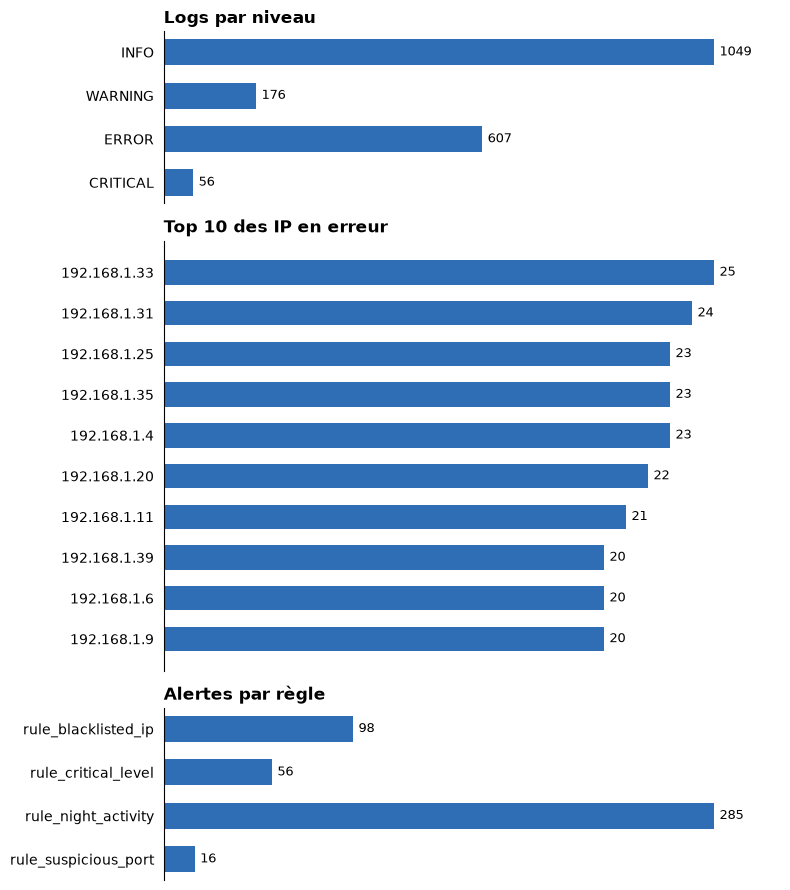

In [17]:
BAR_COLOR = "#2F6DB5"


def bar_chart(axis, title, labels, values):
    positions = range(len(labels))
    axis.barh(positions, values, color=BAR_COLOR, height=0.6)
    axis.set_yticks(positions, labels)
    axis.invert_yaxis()
    axis.set_title(title, loc="left", fontsize=12, fontweight="bold")
    axis.bar_label(axis.containers[0], padding=4, fontsize=9)
    axis.spines[["top", "right", "bottom"]].set_visible(False)
    axis.tick_params(left=False, bottom=False, labelbottom=False)
    axis.margins(x=0.12)


figure, axes = plt.subplots(3, 1, figsize=(8, 9), height_ratios=[4, 10, 4])
bar_chart(axes[0], "Logs par niveau", list(report["by_level"]), list(report["by_level"].values()))
top_ips = report["top_error_ips"]
bar_chart(axes[1], "Top 10 des IP en erreur", [ip for ip, _ in top_ips], [n for _, n in top_ips])
counts = report["alerts"]["counts"]
bar_chart(axes[2], "Alertes par règle", list(counts), list(counts.values()))
figure.tight_layout()
plt.show()

## Ce qu'on a ajouté en plus du sujet

- **Un générateur de logs de test** (`scripts/generate_logs.py`) : il fabrique des logs réalistes avec 5 % de lignes cassées, des niveaux en minuscules, des protocoles inconnus, et **4 attaques cachées à des positions connues**, dont une IP piège. On sait donc à l'avance ce que le programme doit trouver, et les tests le vérifient. Avec la même graine, il produit toujours le même fichier.
- **Des mesures réelles** de mémoire, jusqu'à 1 million de lignes.
- **Un moteur qui survit aux bugs** : une règle qui plante n'arrête pas les autres.
- **Des règles choisies à la ligne de commande** (`--rules port night`) grâce au dictionnaire de fonctions.

## Limites et pistes d'amélioration

- **Deux passages sur les fichiers :** l'agrégation puis les règles relisent les logs. Sur un vrai flux réseau, qu'on ne peut pas relire, il faudrait tout faire en un seul passage.
- **Mémoire de la force brute :** on garde chaque tentative par IP. Garder seulement la série d'échecs en cours rendrait la mémoire constante.
- **Temps entre les échecs :** 5 échecs en 2 secondes ou en 2 jours comptent pareil. Une vraie détection regarderait la durée.
- **Validation des IP :** la regex accepte `999.1.1`. Le module `ipaddress` serait plus strict.
- **`tracemalloc` ralentit beaucoup** l'exécution : il sert à la mesure, on l'enlèverait en production.